# import necessary libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# FILLING USING interpolation

Method	Description

'linear'     : Default. Linearly interpolates between values.

'time'	     : Assumes index is datetime and interpolates accordingly.

'polynomial' : Uses a polynomial curve (e.g., 2nd order).

'spline'     : Spline interpolation (smooth curve).

'nearest'    : Fills with the nearest known value.

'pad'        : Forward fill — propagates last known value forward.

'bfill'      : Backward fill — propagates next known value backward.

In [2]:
# Example data with missing values
data = {'Age': [44, np.nan, 25, np.nan, 100, 14, 30, 22, np.nan, 18]}
df = pd.DataFrame(data)
# Display the initial DataFrame
print("Initial DataFrame:")
print(df)

Initial DataFrame:
     Age
0   44.0
1    NaN
2   25.0
3    NaN
4  100.0
5   14.0
6   30.0
7   22.0
8    NaN
9   18.0


In [3]:
# Fill using linear interpolation
df['Age'] = df['Age'].interpolate(method='linear')

print(df)

     Age
0   44.0
1   34.5
2   25.0
3   62.5
4  100.0
5   14.0
6   30.0
7   22.0
8   20.0
9   18.0


In [4]:
# Example data with missing values
data = {'Age': [22, np.nan, 25, np.nan, 28, 30]}
df = pd.DataFrame(data)
# Display the initial DataFrame
print("Initial DataFrame:")
print(df)

Initial DataFrame:
    Age
0  22.0
1   NaN
2  25.0
3   NaN
4  28.0
5  30.0


In [ ]:
# Fill using linear interpolation
df['Age'] = df['Age'].interpolate(method='linear')

print(df)

    Age
0  22.0
1  23.5
2  25.0
3  26.5
4  28.0
5  30.0


In [ ]:
df['Age'] = df['Age'].interpolate(method='polynomial', order=2)
print(df)

         Age
0  22.000000
1  23.529412
2  25.000000
3  26.411765
4  28.000000
5  30.000000


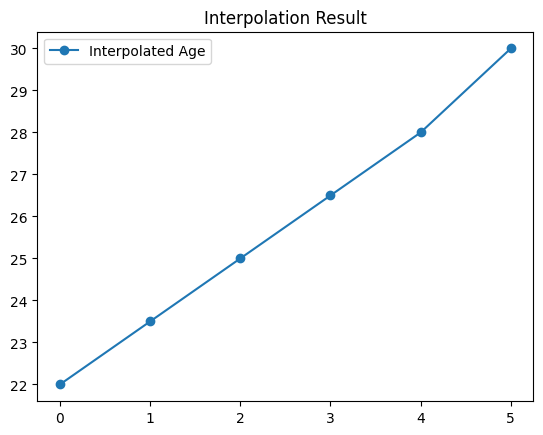

In [19]:
import matplotlib.pyplot as plt

df['Age'].plot(marker='o', label='Interpolated Age')
plt.legend()
plt.title("Interpolation Result")
plt.show()


#  compare between different types of interpolation

In [2]:
# Sample dataframe (replace this with your actual df)
df = pd.DataFrame({
    'Age': [25, np.nan, 30, np.nan, np.nan, 40, 45, np.nan, 50]
})

# Interpolation methods
df['Linear'] = df['Age'].interpolate(method='linear')
df['Polynomial'] = df['Age'].interpolate(method='polynomial', order=2)
df['Spline'] = df['Age'].interpolate(method='spline', order=2)

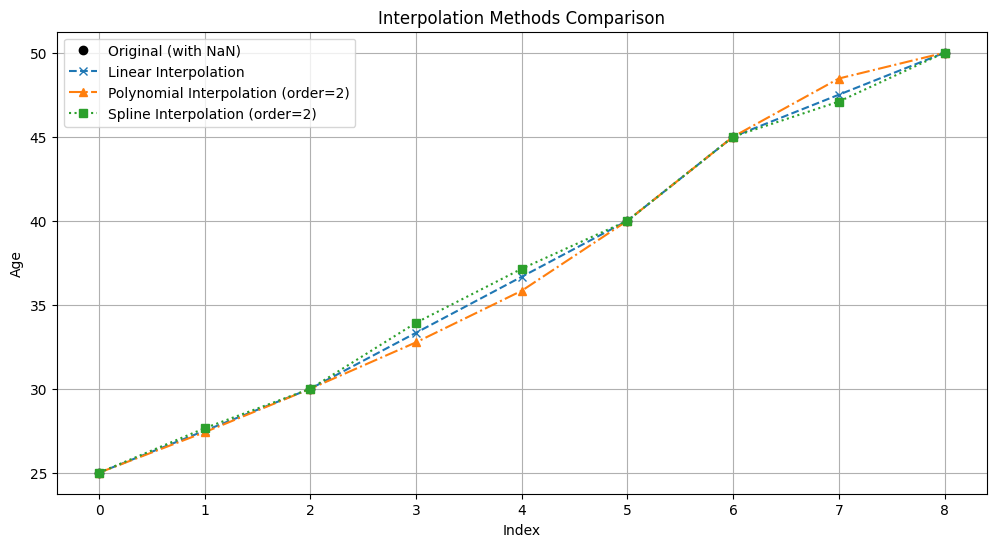

In [3]:
# Plotting all for comparison
plt.figure(figsize=(12, 6))
plt.plot(df['Age'], label='Original (with NaN)', marker='o', linestyle='None', color='black')
plt.plot(df['Linear'], label='Linear Interpolation', linestyle='--', marker='x')
plt.plot(df['Polynomial'], label='Polynomial Interpolation (order=2)', linestyle='-.', marker='^')
plt.plot(df['Spline'], label='Spline Interpolation (order=2)', linestyle=':', marker='s')
plt.title('Interpolation Methods Comparison')
plt.xlabel('Index')
plt.ylabel('Age')
plt.legend()
plt.grid(True)
plt.show()

# handle outliers using interpolation

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('Churn_Modelling.csv')
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
df.drop(['RowNumber', 'CustomerId', 'Surname' , "Exited"], axis=1, inplace=True)

In [4]:
df.isnull().sum()

CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

In [7]:
import numpy as np

In [9]:
numeric_features

['CreditScore',
 'Age',
 'Tenure',
 'Balance',
 'NumOfProducts',
 'HasCrCard',
 'IsActiveMember',
 'EstimatedSalary']

In [10]:
categorical_features

['Geography', 'Gender']

In [8]:
numeric_features = df.select_dtypes(include=[np.int64, np.float64]).columns.tolist()
categorical_features = df.select_dtypes(include=[object]).columns.tolist()

C:\Users\Mahmoud\AppData\Local\Temp\ipykernel_14628\620092460.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(include=[object]).columns.tolist()


In [17]:
# Function to calculate outliers using IQR
def detect_outliers_iqr(data, feature):
    Q1 = data[feature].quantile(0.25)
    Q3 = data[feature].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = data[(data[feature] < lower_bound) | (data[feature] > upper_bound)]
    return outliers

# Check outliers in each numerical column
for col in numeric_features:
    outliers = detect_outliers_iqr(df, col)
    print(f"{col}: {len(outliers)} outliers")

CreditScore: 0 outliers
Age: 167 outliers
Tenure: 0 outliers
Balance: 0 outliers
NumOfProducts: 0 outliers
HasCrCard: 0 outliers
IsActiveMember: 0 outliers
EstimatedSalary: 0 outliers


In [18]:
def fill_outliers_with_interpolation(data, feature, method='linear'):
    """
    Replaces outliers in a specific feature using IQR method, then fills them using interpolation.

    Parameters:
    - data (pd.DataFrame): The DataFrame containing the data.
    - feature (str): The feature/column to process.
    - method (str): Interpolation method (e.g., 'linear', 'polynomial', 'spline', 'time').

    Returns:
    - pd.DataFrame: Modified DataFrame with outliers interpolated.
    """
    Q1 = data[feature].quantile(0.25)
    Q3 = data[feature].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Replace outliers with NaN
    data[feature] = data[feature].apply(lambda x: np.nan if x < lower_bound or x > upper_bound else x)

    # Interpolate missing values (i.e., former outliers)
    data[feature] = data[feature].interpolate(method=method, limit_direction='both')

    return data

In [14]:
df.columns

Index(['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance',
       'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary'],
      dtype='str')

In [21]:
outliers_cols = ['CreditScore', 'Age', 'NumOfProducts']
for col in outliers_cols:
    df = fill_outliers_with_interpolation(df, col, method='linear')  # or 'polynomial', 'spline', etc.
print("Data after filling outliers with interpolation:")
print(df[outliers_cols].head())

Data after filling outliers with interpolation:
   CreditScore   Age  NumOfProducts
0        619.0  42.0            1.0
1        608.0  41.0            1.0
2        502.0  42.0            3.0
3        699.0  39.0            2.0
4        850.0  43.0            1.0


In [22]:
# Check outliers in each numerical column
for col in numeric_features:
    outliers = detect_outliers_iqr(df, col)
    print(f"{col}: {len(outliers)} outliers")

CreditScore: 0 outliers
Age: 0 outliers
Tenure: 0 outliers
Balance: 0 outliers
NumOfProducts: 0 outliers
HasCrCard: 0 outliers
IsActiveMember: 0 outliers
EstimatedSalary: 0 outliers
